In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.preprocessing import RobustScaler      
from sklearn.decomposition import PCA

**LOAD DATASET**

In [2]:
data = pd.read_csv('Bangladesh_Crime_Dataset_B.csv')
data

,Unnamed: 0,incident_month,incident_week,incident_weekday,weekend,part_of_the_day,incident_district,incident_division,precip,visibility,...,average_household_size,density_per_kmsq,literacy_rate,religious_institution,playground,park,police_station,school,college,crime
0,0,7,29,wednesday,0,morning,dhaka,dhaka,6.1,10,...,8.42,30551,74.6,4289,99,17,60,242,64,murder
1,1,1,2,wednesday,0,night,dhaka,dhaka,0.0,10,...,8.42,30551,74.6,4289,99,17,60,242,64,murder
2,2,1,4,tuesday,0,night,dhaka,dhaka,0.0,10,...,8.42,30551,74.6,4289,99,17,60,242,64,murder
3,3,3,9,friday,1,night,dhaka,dhaka,0.0,10,...,8.42,30551,74.6,4289,99,17,60,242,64,murder
4,4,8,34,thursday,0,night,dhaka,dhaka,21.9,9,...,8.42,30551,74.6,4289,99,17,60,242,64,murder
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6569,6569,3,10,tuesday,0,night,munshiganj,dhaka,8.5,9,...,4.55,1399,57.1,365,27,0,1,17,3,robbery
6570,6570,10,42,saturday,1,night,munshiganj,dhaka,2.6,10,...,4.55,1399,57.1,365,27,0,1,17,3,robbery
6571,6571,3,10,tuesday,0,night,munshiganj,dhaka,NaN,9,...,4.55,1399,57.1,365,27,0,1,17,3,robbery
6572,6572,1,2,wednesday,0,night,sylhet,sylhet,0.0,10,...,5.82,893,49.4,359,1,0,1,19,3,robbery


In [3]:
data.head(7)

,Unnamed: 0,incident_month,incident_week,incident_weekday,weekend,part_of_the_day,incident_district,incident_division,precip,visibility,...,average_household_size,density_per_kmsq,literacy_rate,religious_institution,playground,park,police_station,school,college,crime
0,0,7,29,wednesday,0,morning,dhaka,dhaka,6.1,10,...,8.42,30551,74.6,4289,99,17,60,242,64,murder
1,1,1,2,wednesday,0,night,dhaka,dhaka,0.0,10,...,8.42,30551,74.6,4289,99,17,60,242,64,murder
2,2,1,4,tuesday,0,night,dhaka,dhaka,0.0,10,...,8.42,30551,74.6,4289,99,17,60,242,64,murder
3,3,3,9,friday,1,night,dhaka,dhaka,0.0,10,...,8.42,30551,74.6,4289,99,17,60,242,64,murder
4,4,8,34,thursday,0,night,dhaka,dhaka,21.9,9,...,8.42,30551,74.6,4289,99,17,60,242,64,murder
5,5,8,34,thursay,0,night,dhaka,dhaka,21.9,9,...,8.42,30551,74.6,4289,99,17,60,242,64,murder
6,6,2,7,sunday,0,night,dhaka,dhaka,0.6,10,...,3.77,4948,68.0,1118,78,3,6,42,10,murder


In [4]:
data.tail(7)

,Unnamed: 0,incident_month,incident_week,incident_weekday,weekend,part_of_the_day,incident_district,incident_division,precip,visibility,...,average_household_size,density_per_kmsq,literacy_rate,religious_institution,playground,park,police_station,school,college,crime
6567,6567,10,44,wednesday,0,morning,satkhira,khulna,0.0,10,...,4.13,889,50.9,577,230,0,7,60,10,robbery
6568,6568,7,31,tuesday,0,night,satkhira,khulna,14.6,9,...,4.13,889,50.9,577,230,0,7,60,10,robbery
6569,6569,3,10,tuesday,0,night,munshiganj,dhaka,8.5,9,...,4.55,1399,57.1,365,27,0,1,17,3,robbery
6570,6570,10,42,saturday,1,night,munshiganj,dhaka,2.6,10,...,4.55,1399,57.1,365,27,0,1,17,3,robbery
6571,6571,3,10,tuesday,0,night,munshiganj,dhaka,NaN,9,...,4.55,1399,57.1,365,27,0,1,17,3,robbery
6572,6572,1,2,wednesday,0,night,sylhet,sylhet,0.0,10,...,5.82,893,49.4,359,1,0,1,19,3,robbery
6573,6573,1,4,tuesday,0,night,pirojpur,barisal,0.0,10,...,4.44,816,61.2,286,12,0,2,12,2,robbery


### **EXPLORATORY DATA ANALYSIS**

**DATA OVERVIEW**

In [5]:
# Check data dimension
data.shape

(6574, 26)

In [7]:
# data columns
data.columns

Index(['Unnamed: 0', 'incident_month', 'incident_week', 'incident_weekday',
       'weekend', 'part_of_the_day', 'incident_district', 'incident_division',
       'precip', 'visibility', 'heatindex', 'season', 'male_population',
       'female_population', 'total_population', 'gender_ration',
       'average_household_size', 'density_per_kmsq', 'literacy_rate',
       'religious_institution', 'playground', 'park', 'police_station',
       'school', 'college', 'crime'],
      dtype='object')

In [8]:
# Check data information
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6574 entries, 0 to 6573
Data columns (total 26 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Unnamed: 0              6574 non-null   int64  
 1   incident_month          6574 non-null   int64  
 2   incident_week           6574 non-null   int64  
 3   incident_weekday        6574 non-null   object 
 4   weekend                 6574 non-null   int64  
 5   part_of_the_day         6457 non-null   object 
 6   incident_district       6574 non-null   object 
 7   incident_division       6574 non-null   object 
 8   precip                  5917 non-null   float64
 9   visibility              6574 non-null   int64  
 10  heatindex               6574 non-null   int64  
 11  season                  6246 non-null   object 
 12  male_population         6574 non-null   int64  
 13  female_population       6574 non-null   int64  
 14  total_population        6574 non-null   

In [9]:
# Cek missing values
data.isnull().sum()

Unnamed: 0                  0
incident_month              0
incident_week               0
incident_weekday            0
weekend                     0
part_of_the_day           117
incident_district           0
incident_division           0
precip                    657
visibility                  0
heatindex                   0
season                    328
male_population             0
female_population           0
total_population            0
gender_ration               0
average_household_size      0
density_per_kmsq            0
literacy_rate             328
religious_institution       0
playground                  0
park                        0
police_station              0
school                      0
college                     0
crime                       0
dtype: int64

In [10]:
# Cek duplicates
print(f"Number of Duplicated data  : {data.duplicated().sum()}")

Number of Duplicated data  : 0


In [11]:
# Check summary statistics
data.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,6574.0,3.286500e+03,1.897895e+03,0.00,1643.25,3286.50,4929.75,6573.00
incident_month,6574.0,6.193185e+00,3.321934e+00,1.00,3.00,6.00,9.00,12.00
incident_week,6574.0,2.519395e+01,1.451796e+01,1.00,13.00,25.00,37.00,53.00
weekend,6574.0,2.738059e-01,4.459445e-01,0.00,0.00,0.00,1.00,1.00
precip,5917.0,6.136775e+00,1.177835e+01,0.00,0.00,0.80,7.40,204.60
visibility,6574.0,9.488287e+00,9.227419e-01,4.00,9.00,10.00,10.00,10.00
heatindex,6574.0,3.159766e+01,5.502593e+00,15.00,27.00,33.00,36.00,43.00
male_population,6574.0,8.936342e+05,1.605205e+06,11320.00,131930.00,187229.00,391707.00,4931802.00
female_population,6574.0,7.544586e+05,1.284180e+06,11247.00,133996.00,187017.00,381157.25,3974237.00
total_population,6574.0,1.648104e+06,2.889245e+06,22871.00,265276.00,376550.00,775733.00,8906039.00


In [12]:
# Chech unique values in 'incident_district' column
data['incident_district'].unique()

array(['dhaka', 'gazipur', 'chattogram', 'rajshahi', 'khulna',
       'sirajganj', 'narsingdi', 'lakshmipur', 'manikganj', 'patuakhali',
       'jashore', 'sunamganj', 'bhola', 'satkhira', 'gopalganj',
       'habiganj', 'rangpur', 'tangail', 'sylhet', 'dinajpur', 'kurigram',
       'rangamati', 'lalmonirhat', 'barisal', 'brahmanbaria', 'joypurhat',
       'chuadanga', 'bandarban', 'barguna', 'narayanganj', 'pabna',
       'netrokona', 'naogaon', 'panchagarh', 'kishoreganj', 'bagerhat',
       'rajbari', 'natore', 'moulvibazar', 'noakhali', 'mymensingh',
       'pirojpur', 'faridpur', 'kushtia', 'chapainawabganj', 'bogura',
       'jamalpur', 'comilla', 'coxsbazar', 'feni', 'khagrachhari',
       'nilphamari', 'chandpur', 'gaibandha', 'meherpur', 'jhenaidah',
       'thakurgaon', 'narail', 'jhalakathi', 'munshiganj', 'madaripur',
       'magura', 'sherpur', 'shariatpur'], dtype=object)

In [12]:
data['incident_district'].value_counts()

incident_district
dhaka         1169
chattogram     491
mymensingh     269
jashore        261
dinajpur       209
              ... 
magura          17
sherpur         16
shariatpur      15
kurigram        10
narail          10
Name: count, Length: 64, dtype: int64

In [13]:
# Chech unique values in 'incident_division' column
data['incident_division'].unique()


array(['dhaka', 'gazipur', 'chattogram', 'rajshahi', 'khulna', 'barisal',
       'sylhet', 'rangpur', 'mymensingh'], dtype=object)

In [14]:
data['incident_division'].value_counts()

incident_division
dhaka         2046
chattogram    1061
rajshahi       782
rangpur        703
khulna         697
mymensingh     449
sylhet         424
barisal        408
gazipur          4
Name: count, dtype: int64

In [14]:
# Chech unique values in 'crime' column
data['crime'].unique()

array(['murder', 'rape', 'assault', 'bodyfound', 'kidnap', 'robbery'],
      dtype=object)

In [16]:
data['crime'].value_counts()

crime
murder       1518
bodyfound    1517
rape         1193
assault      1097
kidnap        651
robbery       598
Name: count, dtype: int64

In [15]:
# Chech unique values in 'season' column
data['season'].unique()

array(['rainy', 'winter', 'hot', nan], dtype=object)

In [18]:
data['season'].value_counts()

season
rainy     2716
winter    1831
hot       1699
Name: count, dtype: int64

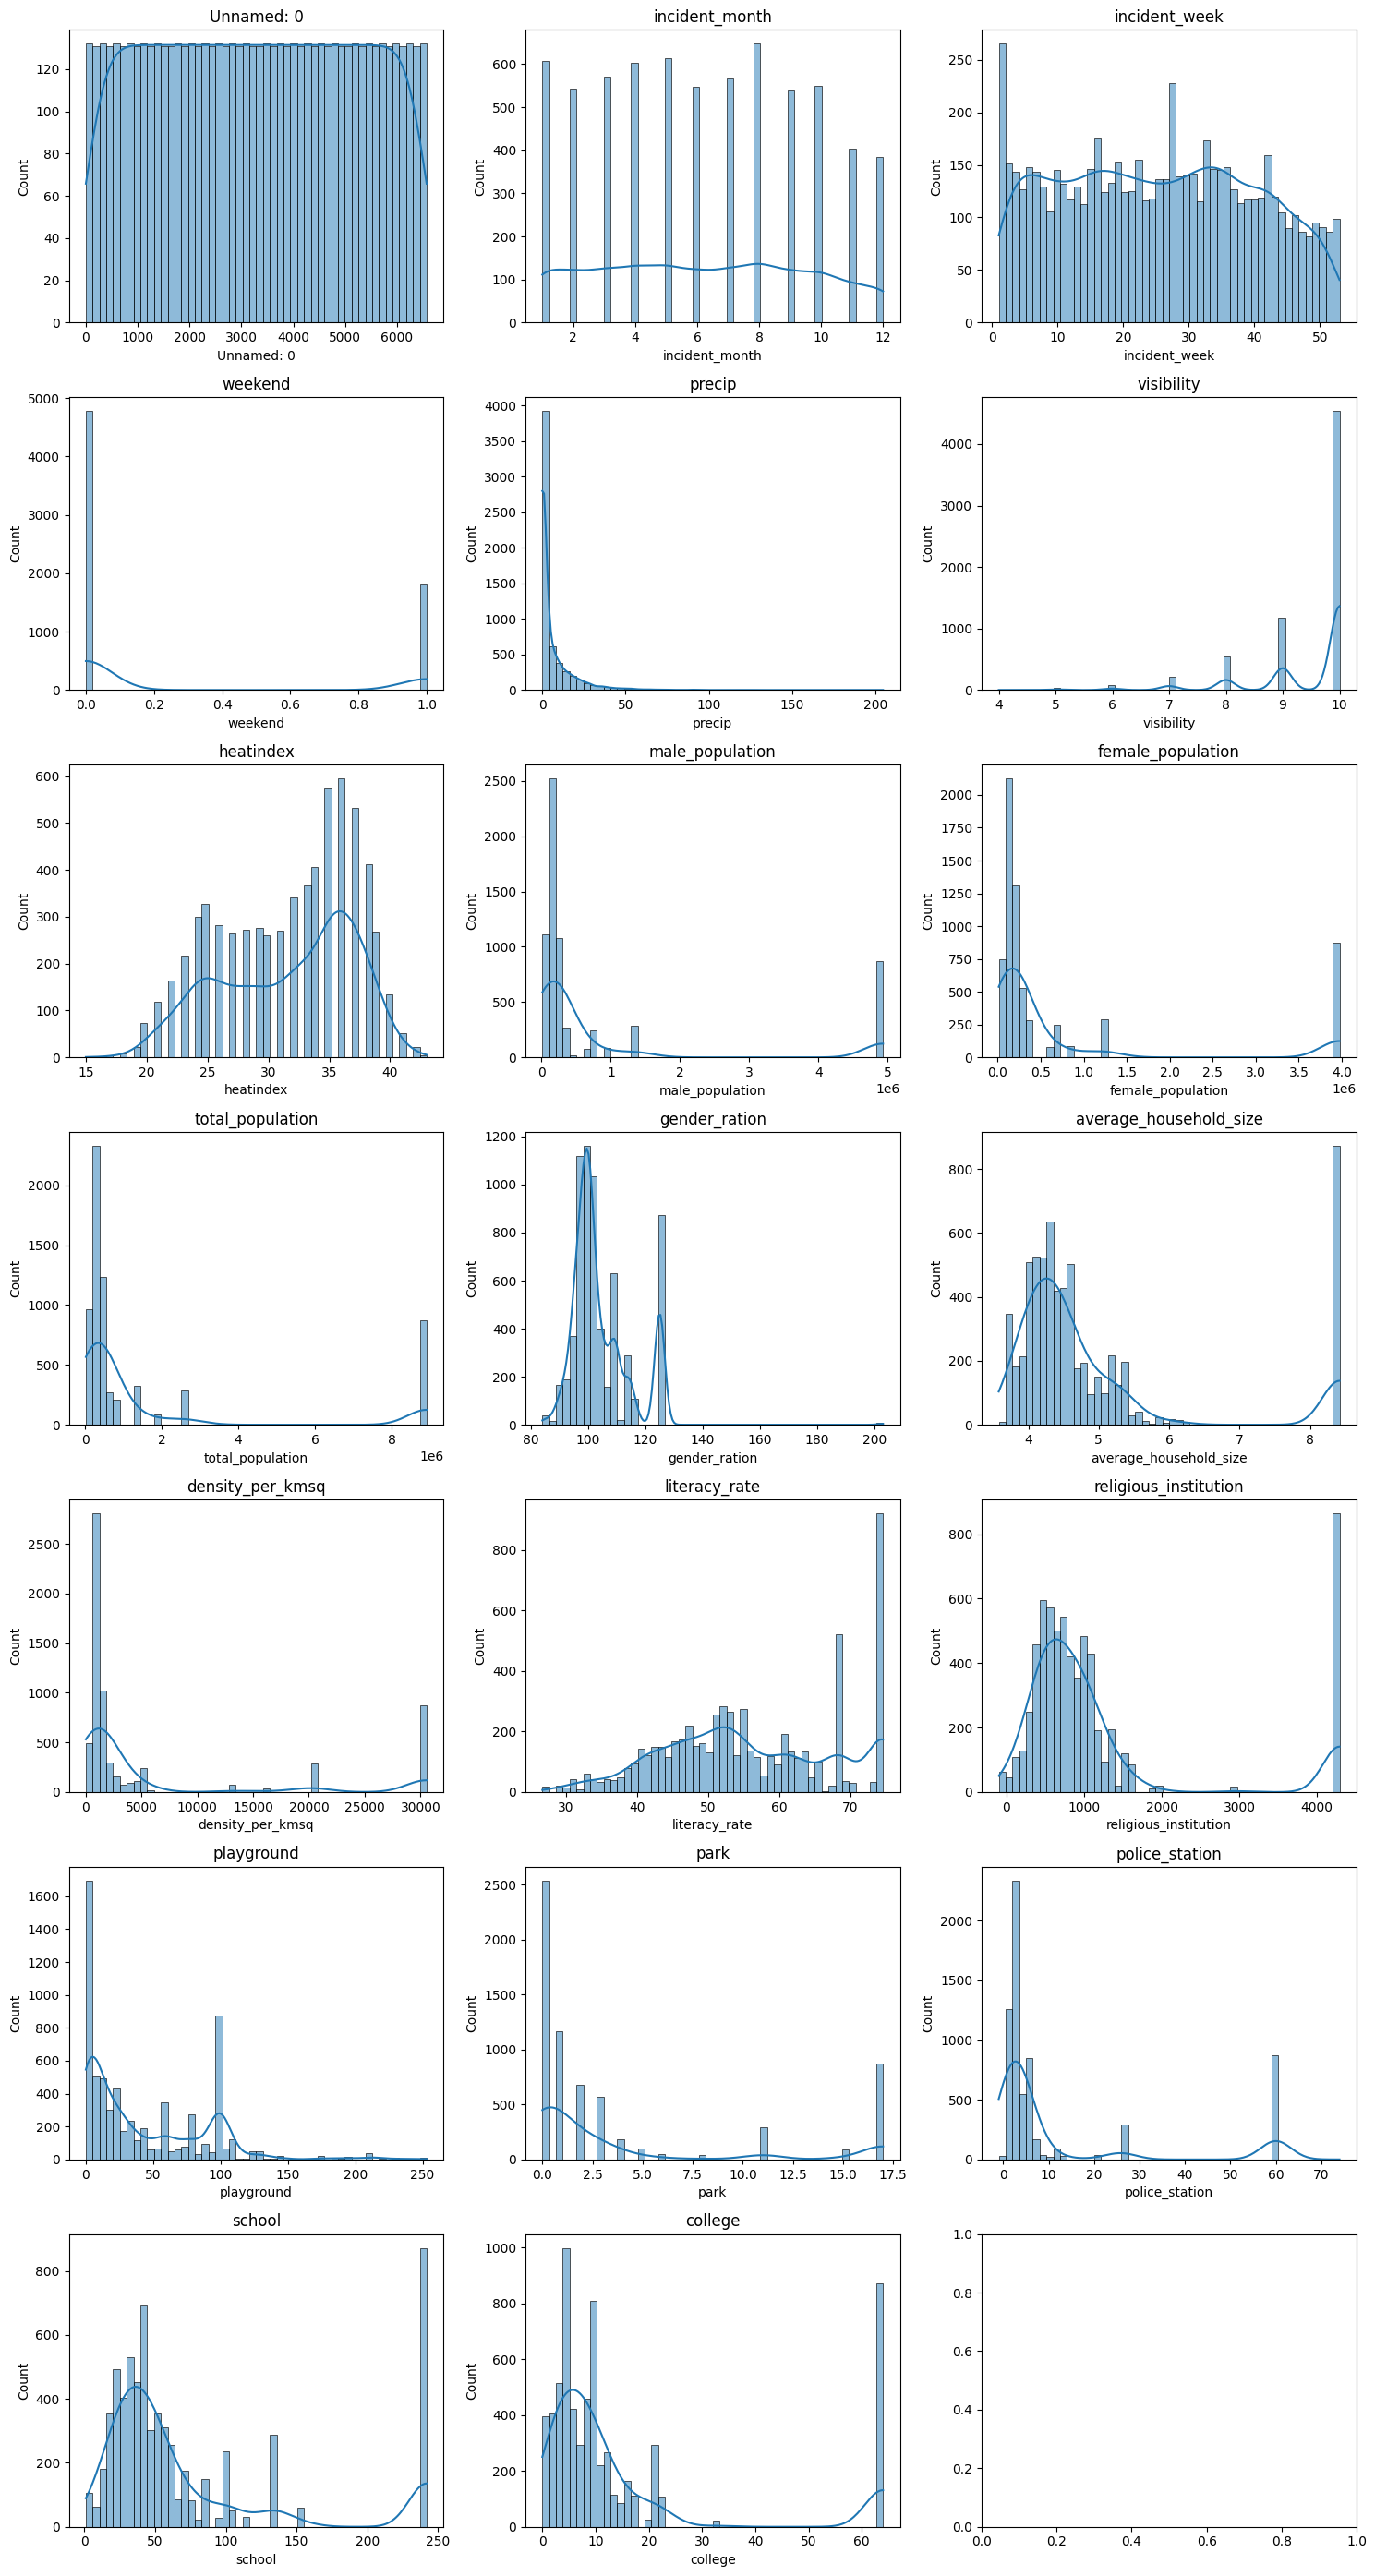

In [16]:
# Cek distribution
num_cols = data.select_dtypes(include=['float64', 'int64']).columns
rows = (len(num_cols) + 2) // 3  
fig, axs = plt.subplots(rows, 3, figsize=(15, 4*rows))
axs = axs.flatten()
for i, col in enumerate(num_cols):
    sns.histplot(data[col], bins=50, kde=True, ax=axs[i])
    axs[i].set_title(col)

plt.tight_layout()
plt.show()

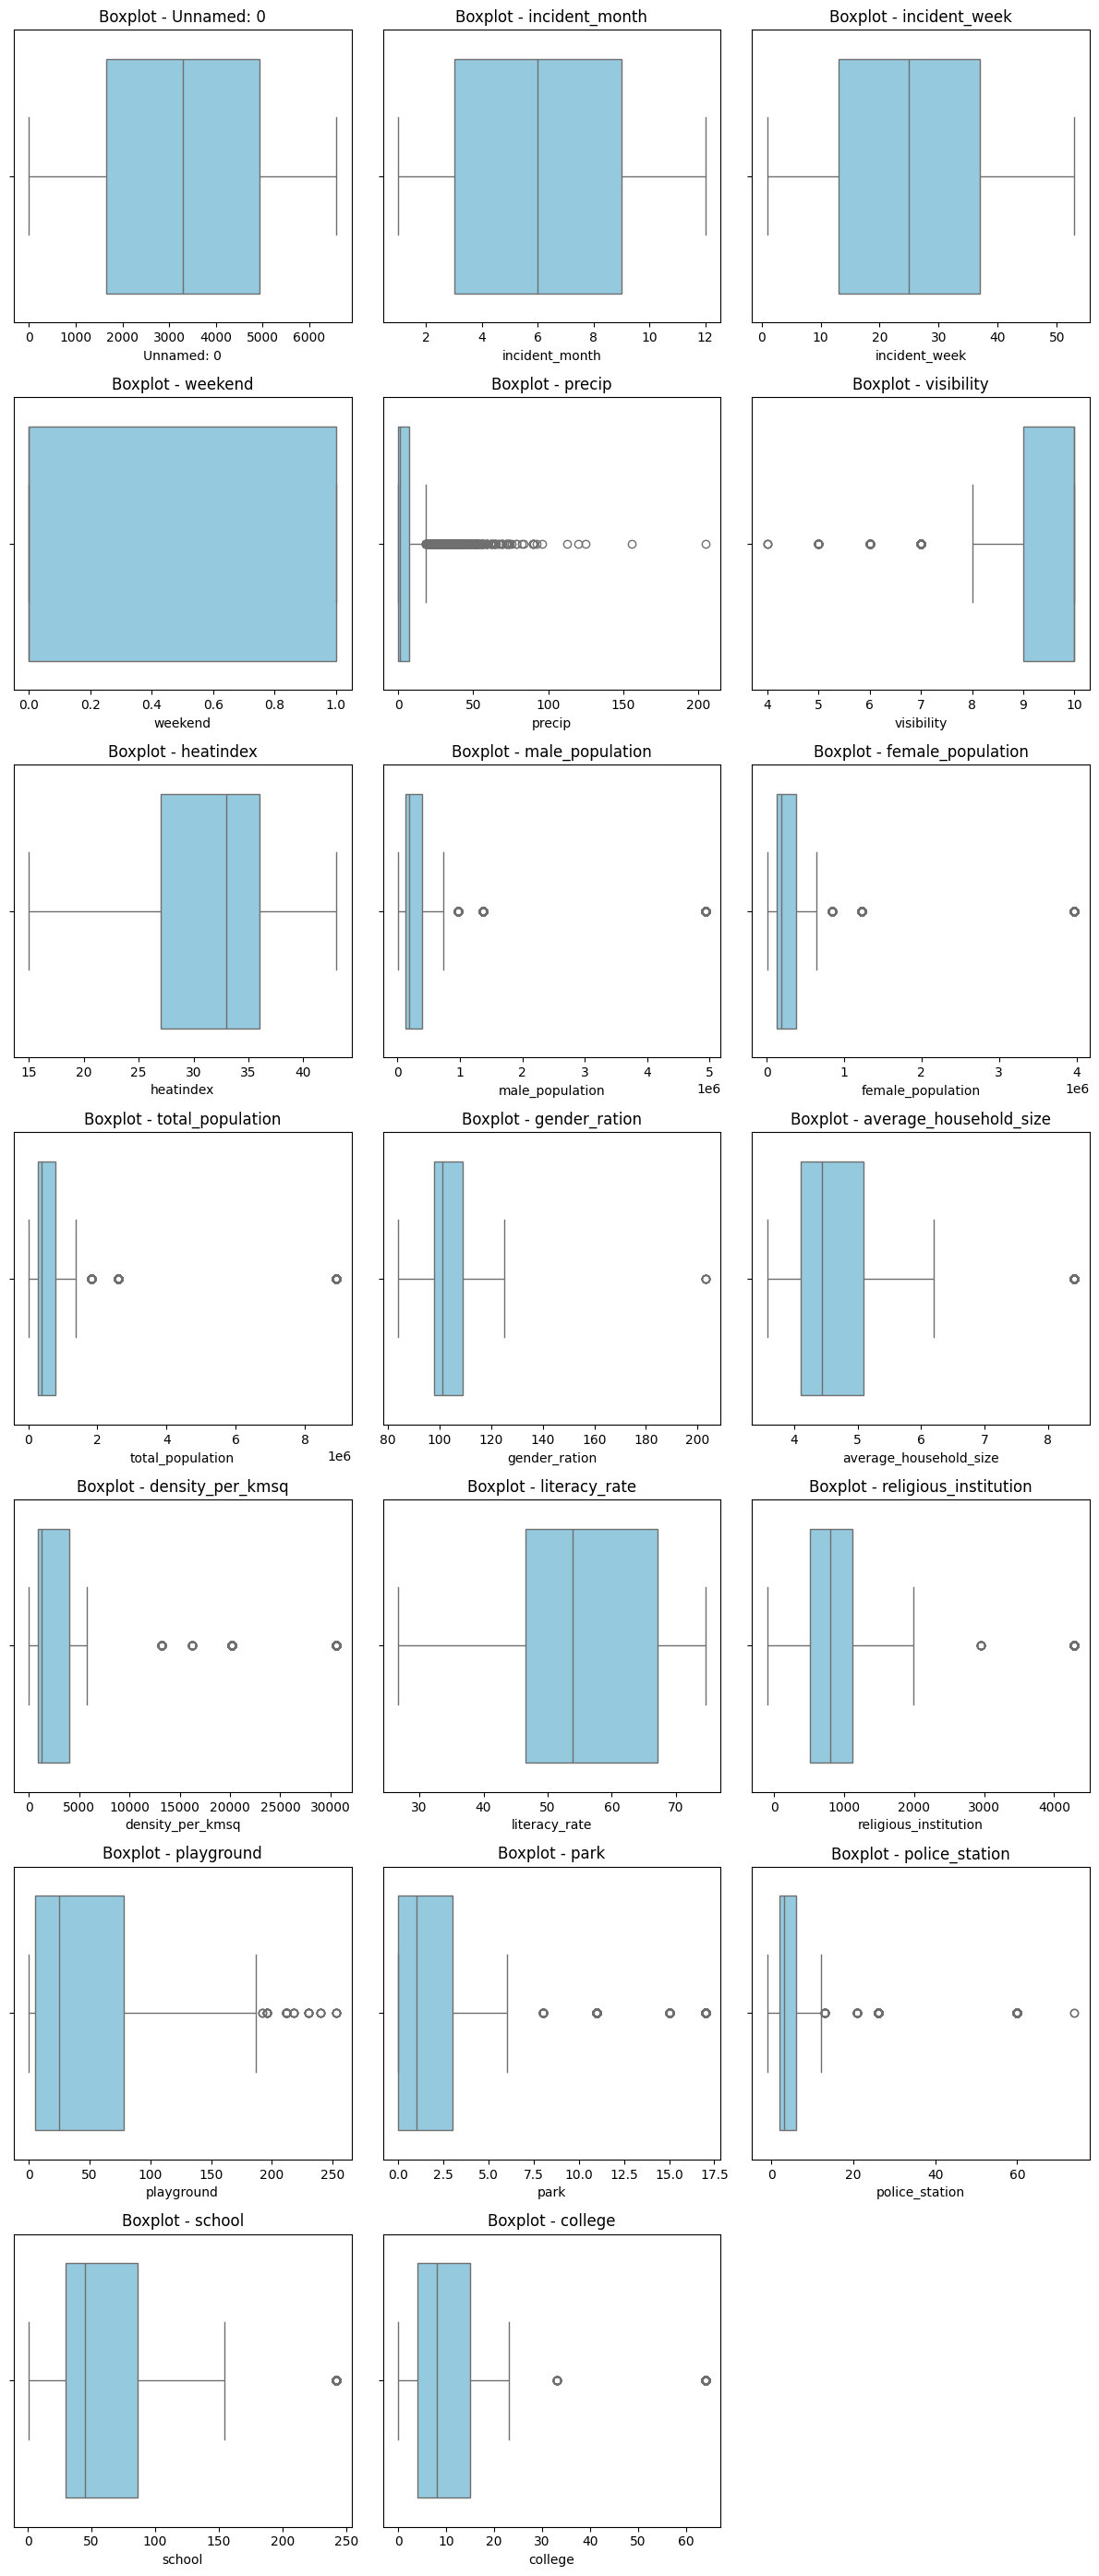

In [17]:
# CHeck outliers with boxplot
n_cols = 3 
n_rows = (len(num_cols) + n_cols - 1) // n_cols 
plt.figure(figsize=(12, 4 * n_rows))
for i, col in enumerate(num_cols, 1):
    plt.subplot(n_rows, n_cols, i)
    sns.boxplot(x=data[col], color='skyblue')
    plt.title(f'Boxplot - {col}')

plt.tight_layout()
plt.show()

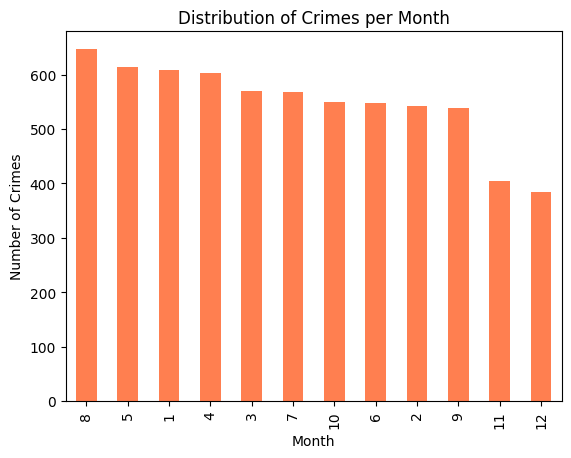

In [76]:
# check distribution of crimes per month
data['incident_month'].value_counts().plot(kind='bar', color='coral')
plt.title('Distribution of Crimes per Month')
plt.xlabel('Month')
plt.ylabel('Number of Crimes')
plt.show()

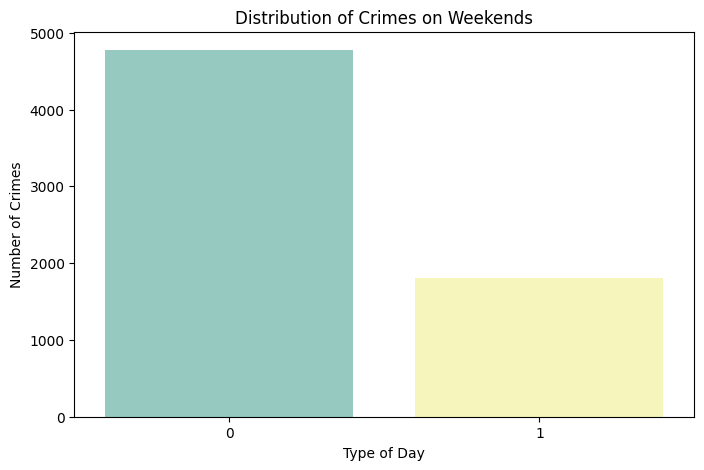

In [78]:
# Crime distribution on weekends
plt.figure(figsize=(8, 5))
sns.countplot(data=data, x='weekend', palette='Set3')
plt.title('Distribution of Crimes on Weekends')
plt.xlabel('Type of Day')
plt.ylabel('Number of Crimes')
plt.show()

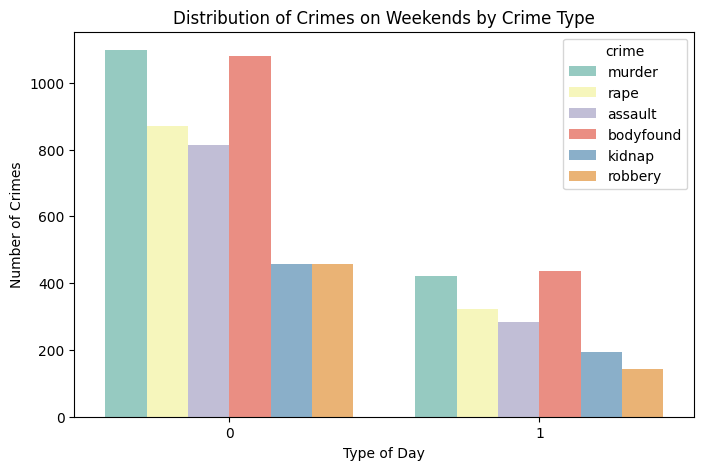

In [79]:
# Crime distribution on weekends by crime type
plt.figure(figsize=(8, 5))
sns.countplot(data=data, x='weekend', hue='crime', palette='Set3')
plt.title('Distribution of Crimes on Weekends by Crime Type')
plt.xlabel('Type of Day')
plt.ylabel('Number of Crimes')
plt.show()

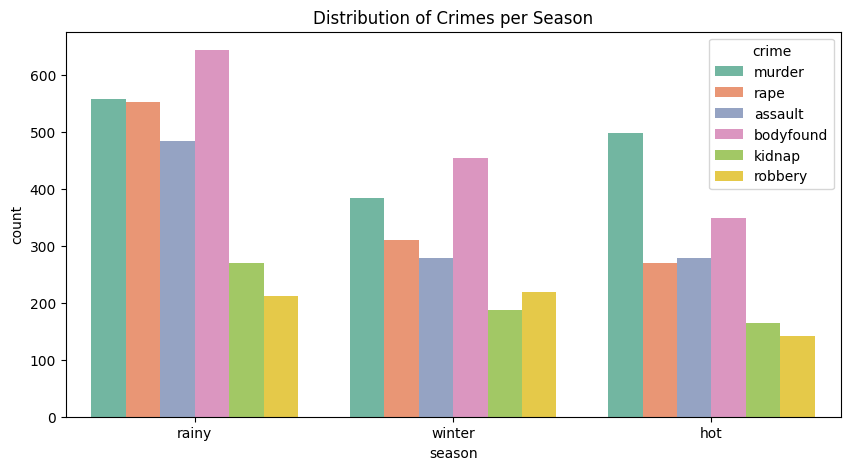

In [80]:
# Crime distribution per season
plt.figure(figsize=(10, 5))
sns.countplot(data=data, x='season', hue='crime', palette='Set2')
plt.title('Distribution of Crimes per Season')
plt.show()

**DATA CONDITION**  
1. There are some Missing values in column part_of_the_day, precip, season, and literacy_rate.
2. There are some Negative values in religious_institution, and police_station.
3. There is no Duplicated issue.
4. There is some outliers on precip and visibilit, and in Total_population, but it's considered as a normal event.

**TIDY UP DATA**

In [ ]:
# Drop unnecessary columns 
data_clean = data.drop(columns=['Unnamed: 0', 'crime']).copy()

In [23]:
# HAndle negative values in religious_institution to nan
data_clean['religious_institution'] = data_clean['religious_institution'].apply(lambda x: np.nan if x < 0 else x)
data_clean['police_station'] = data_clean['police_station'].apply(lambda x: np.nan if x < 0 else x)


In [24]:
data_clean.isnull().sum()

incident_month              0
incident_week               0
incident_weekday            0
weekend                     0
part_of_the_day           117
incident_district           0
incident_division           0
precip                    657
visibility                  0
heatindex                   0
season                    328
male_population             0
female_population           0
total_population            0
gender_ration               0
average_household_size      0
density_per_kmsq            0
literacy_rate             328
religious_institution      65
playground                  0
park                        0
police_station              1
school                      0
college                     0
dtype: int64

In [25]:
# Handle missing values in numerical columns with median
num_cols = data_clean.select_dtypes(include=['float64', 'int64']).columns
for col in num_cols:
    median_value = data_clean[col].median()
    data_clean[col].fillna(median_value, inplace=True)

# Handle missing values in categorical columns with mode
cat_cols = data_clean.select_dtypes(include=['object']).columns
for col in cat_cols:
    mode_value = data_clean[col].mode()[0]
    data_clean[col].fillna(mode_value, inplace=True)

In [26]:
# Final check for missing values
data_clean.isnull().sum()

incident_month            0
incident_week             0
incident_weekday          0
weekend                   0
part_of_the_day           0
incident_district         0
incident_division         0
precip                    0
visibility                0
heatindex                 0
season                    0
male_population           0
female_population         0
total_population          0
gender_ration             0
average_household_size    0
density_per_kmsq          0
literacy_rate             0
religious_institution     0
playground                0
park                      0
police_station            0
school                    0
college                   0
dtype: int64

### **DATA PREPROCESSING**

In [29]:
# Choose Features 

# CHoose numerical features for clustering
X_numeric = data_clean.select_dtypes(include=[np.number]).copy()
print("Features used for Clustering:")
print(X_numeric.columns.tolist())

Features used for Clustering:
['incident_month', 'incident_week', 'weekend', 'precip', 'visibility', 'heatindex', 'male_population', 'female_population', 'total_population', 'gender_ration', 'average_household_size', 'density_per_kmsq', 'literacy_rate', 'religious_institution', 'playground', 'park', 'police_station', 'school', 'college']


In [ ]:
# Scaling the data
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X_numeric)

In [33]:
# Clusstering Evaluation for K = 2 to 10
k_range = range(2, 11)
inertias = []
silhouette_scores = []
davies_bouldin_scores = []
calinski_harabasz_scores = []


for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X_scaled)
    
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, cluster_labels))
    davies_bouldin_scores.append(davies_bouldin_score(X_scaled, cluster_labels))
    calinski_harabasz_scores.append(calinski_harabasz_score(X_scaled, cluster_labels))
    print(f"✓ K = {k} FInished Evaluation")



✓ K = 2 FInished Evaluation
✓ K = 3 FInished Evaluation
✓ K = 4 FInished Evaluation
✓ K = 5 FInished Evaluation
✓ K = 6 FInished Evaluation
✓ K = 7 FInished Evaluation
✓ K = 8 FInished Evaluation
✓ K = 9 FInished Evaluation
✓ K = 10 FInished Evaluation


In [35]:
# Check EValuation Results
print("Results of Clustering Evaluation Metrics:\n")

for i, k in enumerate(k_range):
    print(f"\nK = {k}:")
    print(f"  • Inertia (WCSS):           {inertias[i]:>12,.2f}  ")
    print(f"  • Skor Silhouette:          {silhouette_scores[i]:>12.4f}  ")
    print(f"  • Indeks Davies-Bouldin:    {davies_bouldin_scores[i]:>12.4f}  ")
    print(f"  • Skor Calinski-Harabasz:   {calinski_harabasz_scores[i]:>12,.2f} ")

print("\n" + "=" * 80)

Results of Clustering Evaluation Metrics:


K = 2:
  • Inertia (WCSS):             101,890.01  
  • Skor Silhouette:                0.8655  
  • Indeks Davies-Bouldin:          0.1464  
  • Skor Calinski-Harabasz:      59,123.67 

K = 3:
  • Inertia (WCSS):              63,250.55  
  • Skor Silhouette:                0.6948  
  • Indeks Davies-Bouldin:          0.4000  
  • Skor Calinski-Harabasz:      49,620.87 

K = 4:
  • Inertia (WCSS):              49,272.85  
  • Skor Silhouette:                0.4968  
  • Indeks Davies-Bouldin:          0.6971  
  • Skor Calinski-Harabasz:      43,079.66 

K = 5:
  • Inertia (WCSS):              40,343.81  
  • Skor Silhouette:                0.4934  
  • Indeks Davies-Bouldin:          0.8038  
  • Skor Calinski-Harabasz:      39,818.13 

K = 6:
  • Inertia (WCSS):              36,569.19  
  • Skor Silhouette:                0.3878  
  • Indeks Davies-Bouldin:          0.9512  
  • Skor Calinski-Harabasz:      35,272.91 

K = 7:
  • Inertia (W

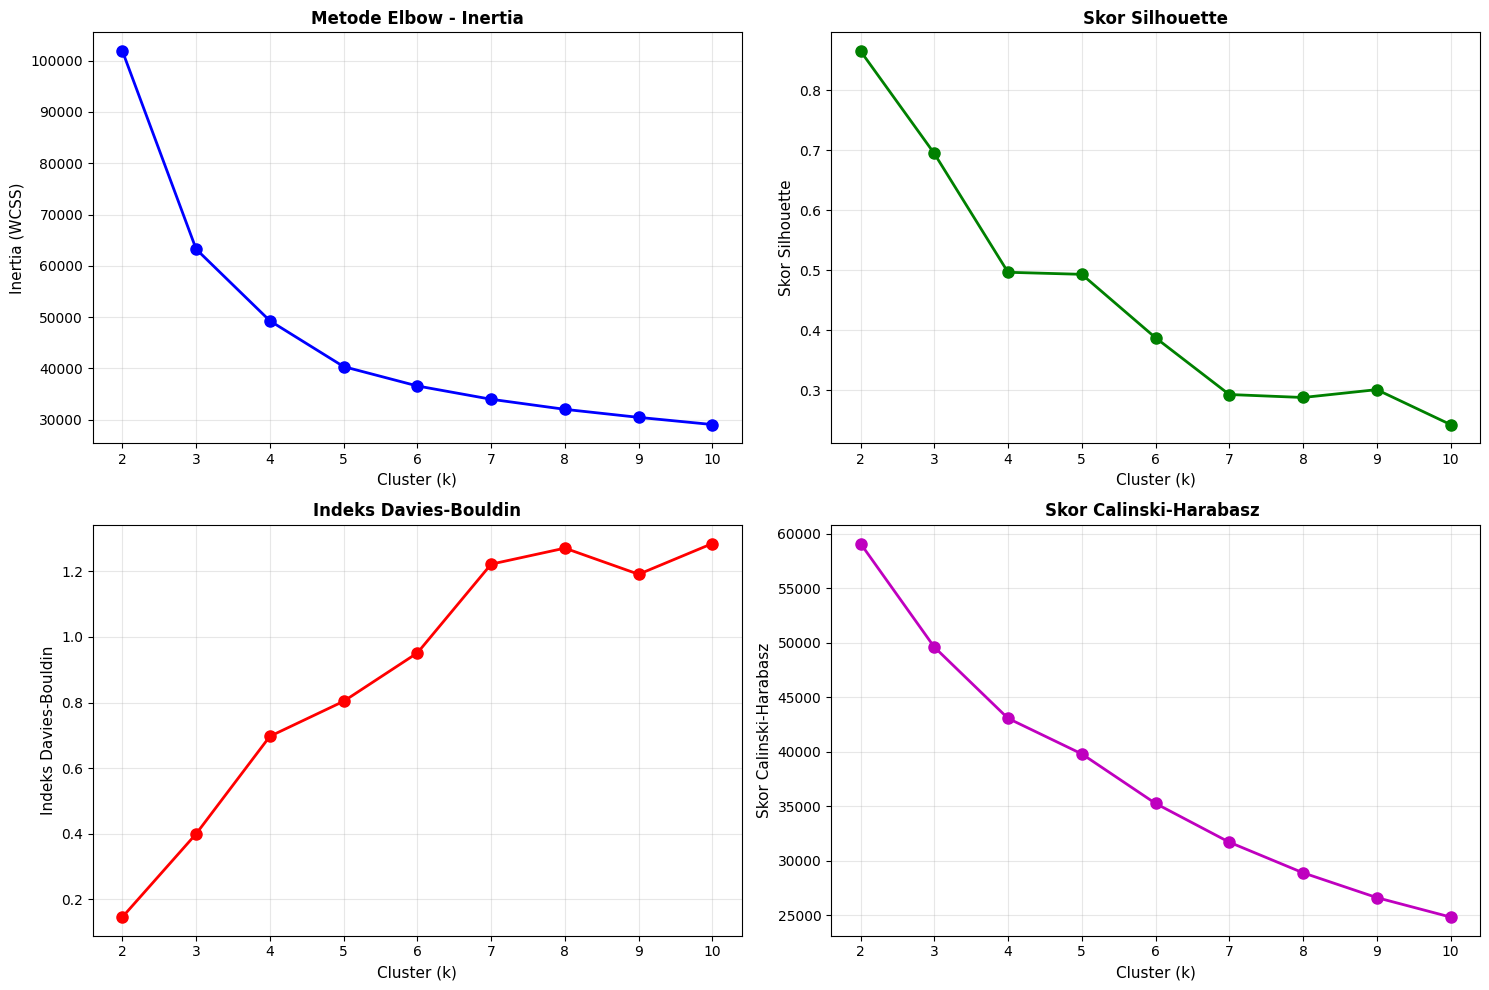

In [72]:
# Decide Best number of clusters K
# Visualize Clustering Evaluation Metrics
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Metode Elbow (Inertia)
axes[0, 0].plot(k_range, inertias, 'bo-', linewidth=2, markersize=8)
axes[0, 0].set_xlabel('Cluster (k)', fontsize=11)
axes[0, 0].set_ylabel('Inertia (WCSS)', fontsize=11)
axes[0, 0].set_title('Metode Elbow - Inertia', fontsize=12, fontweight='bold')
axes[0, 0].grid(True, alpha=0.3)

# 2. Skor Silhouette 
axes[0, 1].plot(k_range, silhouette_scores, 'go-', linewidth=2, markersize=8)
axes[0, 1].set_xlabel('Cluster (k)', fontsize=11)
axes[0, 1].set_ylabel('Skor Silhouette', fontsize=11)
axes[0, 1].set_title('Skor Silhouette', fontsize=12, fontweight='bold')
axes[0, 1].grid(True, alpha=0.3)

# 3. Indeks Davies-Bouldin
axes[1, 0].plot(k_range, davies_bouldin_scores, 'ro-', linewidth=2, markersize=8)
axes[1, 0].set_xlabel('Cluster (k)', fontsize=11)
axes[1, 0].set_ylabel('Indeks Davies-Bouldin', fontsize=11)
axes[1, 0].set_title('Indeks Davies-Bouldin', fontsize=12, fontweight='bold')
axes[1, 0].grid(True, alpha=0.3)

# 4. Skor Calinski-Harabasz 
axes[1, 1].plot(k_range, calinski_harabasz_scores, 'mo-', linewidth=2, markersize=8)
axes[1, 1].set_xlabel('Cluster (k)', fontsize=11)
axes[1, 1].set_ylabel('Skor Calinski-Harabasz', fontsize=11)
axes[1, 1].set_title('Skor Calinski-Harabasz ', fontsize=12, fontweight='bold')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



In [44]:
# Determine the best K based on the metrics
best_k_silhouette = k_range[np.argmax(silhouette_scores)]
best_k_davies = k_range[np.argmin(davies_bouldin_scores)]
best_k_calinski = k_range[np.argmax(calinski_harabasz_scores)]

print(f"Based on Silhouette:        K = {best_k_silhouette} (score: {np.max(silhouette_scores):.4f})")
print(f"Based on Davies-Bouldin:    K = {best_k_davies} (index: {np.min(davies_bouldin_scores):.4f})")
print(f"Based on Calinski-Harabasz: K = {best_k_calinski} (score: {np.max(calinski_harabasz_scores):,.2f})")
print(f"\nCONCLUSION: Using K = {best_k_silhouette} ")

Based on Silhouette:        K = 2 (score: 0.8655)
Based on Davies-Bouldin:    K = 2 (index: 0.1464)
Based on Calinski-Harabasz: K = 2 (score: 59,123.67)

CONCLUSION: Using K = 2 


### **MODELING**

In [ ]:

optimal_k = best_k_silhouette
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=20)
# apply kmeans to scaled data
clusters = kmeans_final.fit_predict(X_scaled)

# add cluster labels to original data
X_numeric['Cluster'] = clusters


In [53]:
# Check Cluster Result Distribution
print(f"\nCluster Sample Distribution:")
for cluster_id in range(optimal_k):
    count = (clusters == cluster_id).sum()
    percentage = count / len(clusters) * 100
    print(f"  Cluster {cluster_id}: {count:>5d} sample ({percentage:>6.2f}%)")




Cluster Sample Distribution:
  Cluster 0:  5702 sample ( 86.74%)
  Cluster 1:   872 sample ( 13.26%)


<Axes: xlabel='Cluster'>

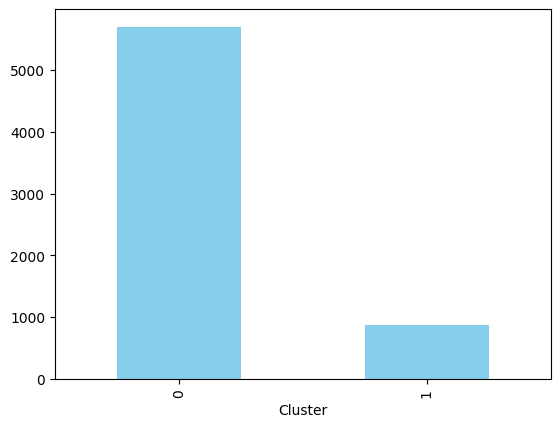

In [47]:
X_numeric['Cluster'].value_counts().sort_index().plot(kind='bar', color='skyblue')

Total Variance: 96.80%
  - PC1 explained: 94.26%
  - PC2 explained: 2.54%


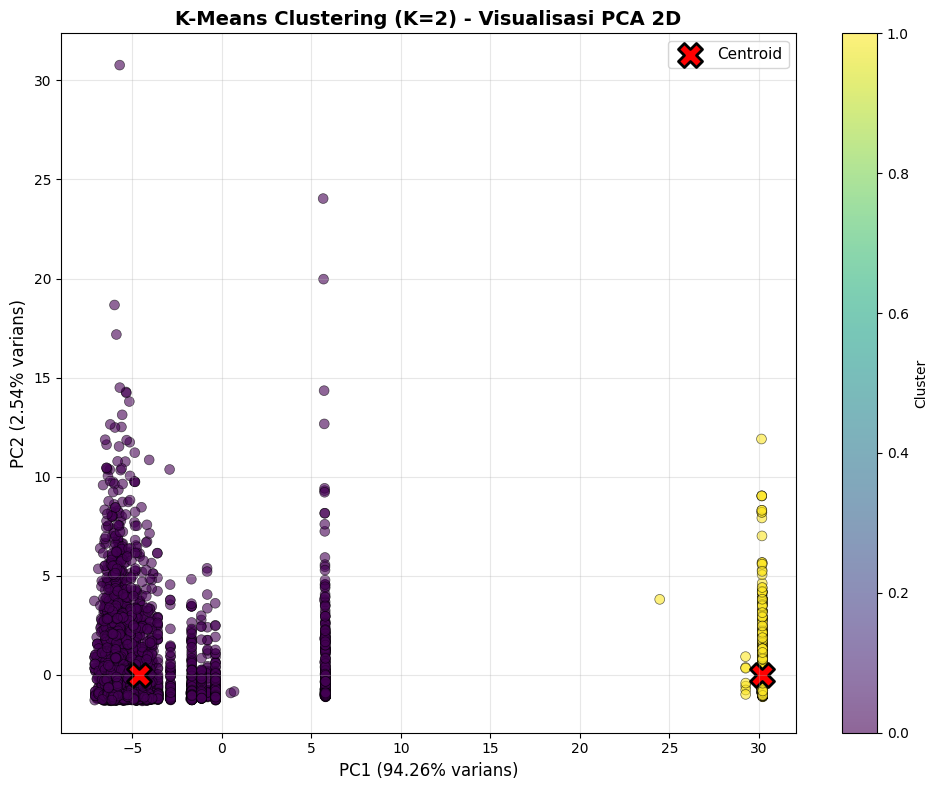

In [75]:
# Visualization using PCA 2D
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)

variance_2d = pca_2d.explained_variance_ratio_.sum()
print(f"Total Variance: {variance_2d:.2%}")
print(f"  - PC1 explained: {pca_2d.explained_variance_ratio_[0]:.2%}")
print(f"  - PC2 explained: {pca_2d.explained_variance_ratio_[1]:.2%}")

plt.figure(figsize=(10, 8))
scatter = plt.scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], 
                     c=clusters, cmap='viridis', 
                     s=50, alpha=0.6, edgecolors='black', linewidth=0.5)

# Plot pusat cluster (ubah ke ruang PCA)
centers_pca = pca_2d.transform(kmeans_final.cluster_centers_)
plt.scatter(centers_pca[:, 0], centers_pca[:, 1], 
           c='red', marker='X', s=300, 
           edgecolors='black', linewidth=2, label='Centroid')

plt.colorbar(scatter, label='Cluster')
plt.xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]:.2%} varians)', fontsize=12)
plt.ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]:.2%} varians)', fontsize=12)
plt.title(f'K-Means Clustering (K={optimal_k}) - Visualisasi PCA 2D', fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
cluster_analysis = X_numeric.copy()

profil_numerik = cluster_analysis.groupby('Cluster').mean().T
profil_kategorikal = data.assign(Cluster=clusters).groupby('Cluster')[['crime', 'incident_division']].agg(lambda x: x.mode()[0]).T

print("--- PROFILING CLUSTER ---")
display(profil_numerik)
display(profil_kategorikal)

--- PROFILING CLUSTER ---


Cluster,0,1
incident_month,6.180989,6.272936e+00
incident_week,25.137320,2.556422e+01
weekend,0.274816,2.672018e-01
precip,5.754262,4.617087e+00
visibility,9.476324,9.566514e+00
heatindex,31.533848,3.201491e+01
male_population,276082.050333,4.931802e+06
female_population,262061.748685,3.974237e+06
total_population,538157.060680,8.906039e+06
gender_ration,101.283935,1.250000e+02


Cluster,0,1
crime,murder,bodyfound
incident_division,dhaka,dhaka


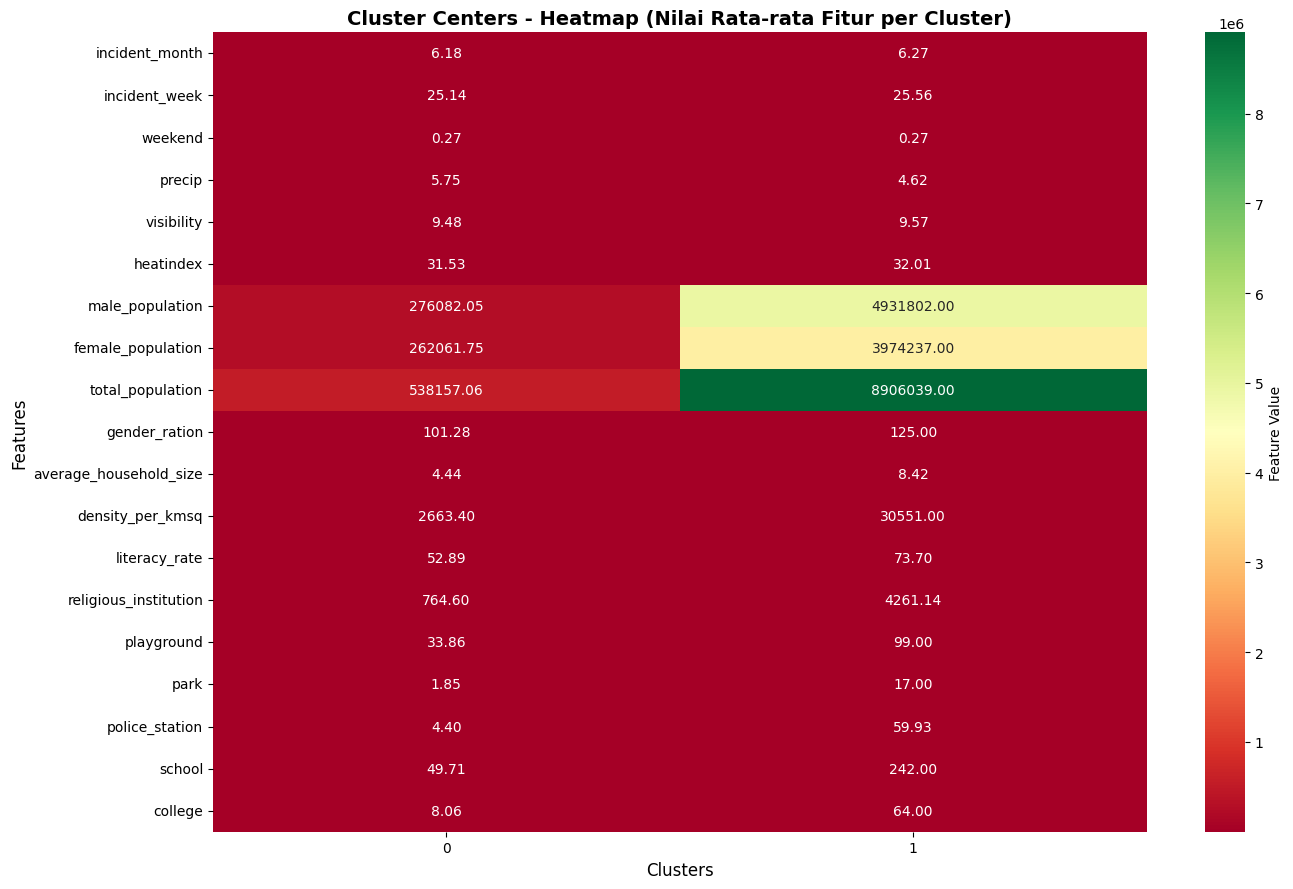

In [68]:
# Heatmap of Cluster Centers
centers_df = pd.DataFrame(
    scaler.inverse_transform(kmeans_final.cluster_centers_),
    columns=X_numeric.columns[:-1]
)
centers_df = centers_df.T

plt.figure(figsize=(14, 9))
sns.heatmap(centers_df, annot=True, fmt='.2f', cmap='RdYlGn', 
            cbar_kws={'label': 'Feature Value'}, 
            xticklabels=centers_df.columns)
plt.title('Cluster Centers - Heatmap (Nilai Rata-rata Fitur per Cluster)', fontsize=14, fontweight='bold')
plt.ylabel('Features', fontsize=12)
plt.xlabel('Clusters', fontsize=12)
plt.tight_layout()
plt.show()

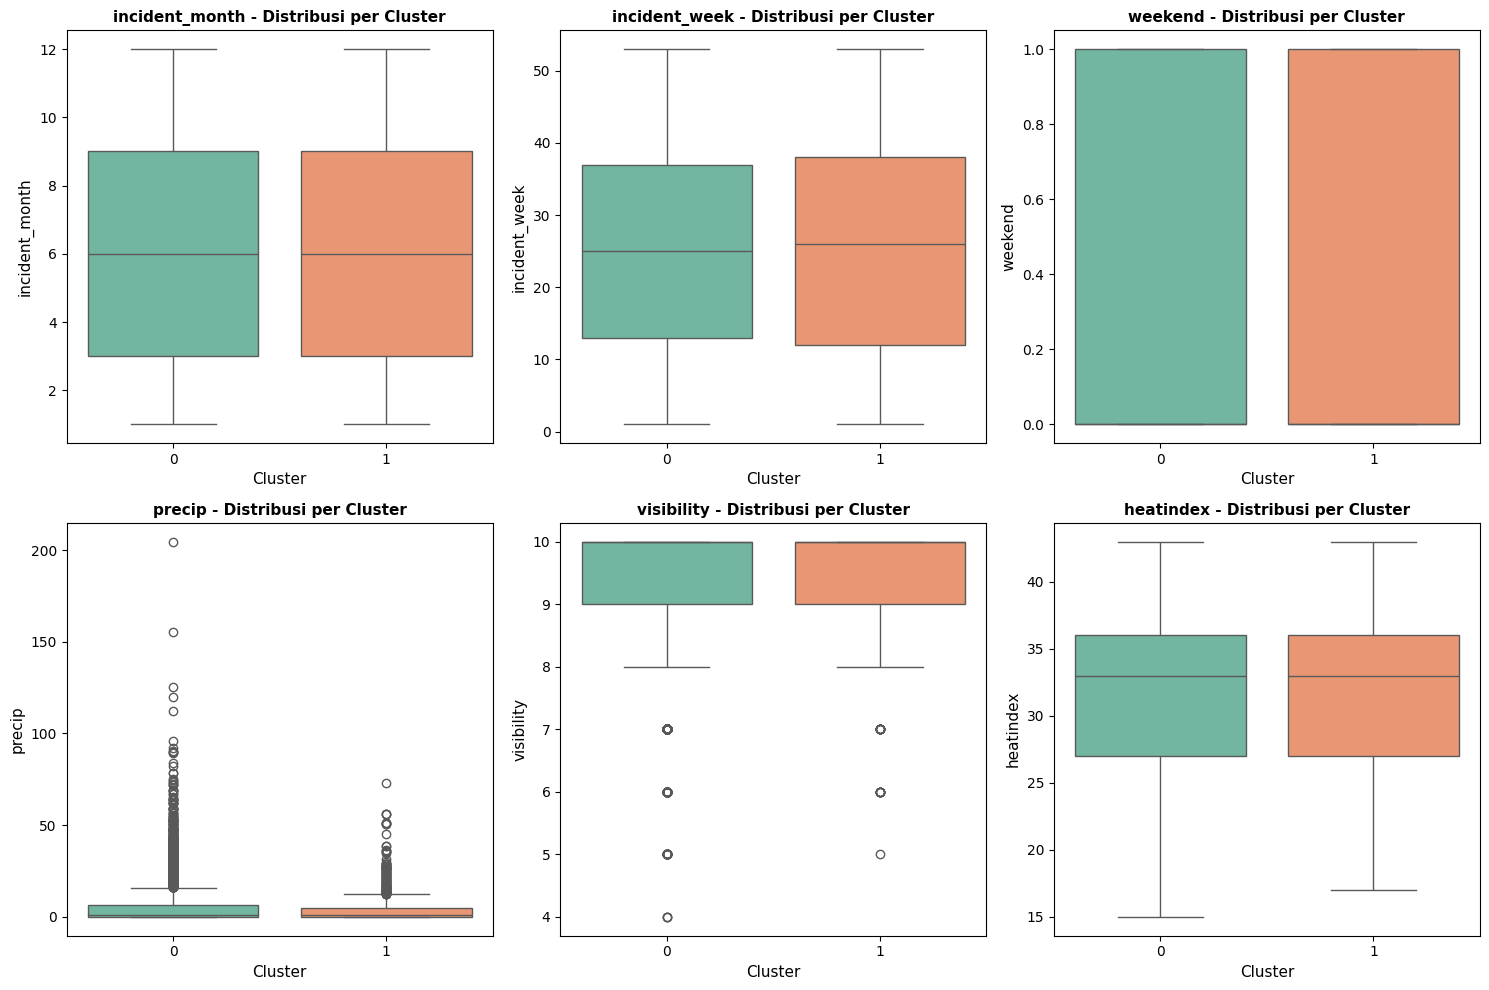

In [70]:
# Boxplot of Important Features per Cluster
important_features = X_numeric.columns[:-1].tolist()[:6] 


fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for idx, feature in enumerate(important_features):
    sns.boxplot(data=cluster_analysis, x='Cluster', y=feature, ax=axes[idx], palette='Set2')
    axes[idx].set_title(f'{feature} - Distribusi per Cluster', fontweight='bold', fontsize=11)
    axes[idx].set_xlabel('Cluster', fontsize=11)
    axes[idx].set_ylabel(feature, fontsize=11)
    
plt.tight_layout()
plt.show()

### **PROFILE**

**CLUSTER 0: RURAL/SEMI-URBAN AREAS**                       
(86.74% of incidents | 5,702 samples)                      

**DEMOGRAPHIC PROFILE:**  
  • Small to Medium Populations: ~538K total (mostly 50K-1M range)  
  • Lower Density: ~2,663 persons/km²   
  • Moderate Literacy: 52.89% average literacy rate  
  • Balanced Gender: 101:100 ratio  
  • Small Households: 4.44 members on average  

**INFRASTRUCTURE CHARACTERISTICS:**  
  • LIMITED Public Services: ~765 religious institutions, ~35 playgrounds, ~2 parks per area  
  • Police Coverage: 4-5 police stations per area (limited coverage)  
  • Education: ~50 schools, ~8 colleges (basic infrastructure)  
  
**ENVIRONMENTAL CONDITIONS:**  
  • Moderate Precipitation: 5.75mm average  
  • High Visibility: 9.48 km  
  • Heat Index: 31.5°C (hot, humid tropical climate)  

**POLICING STRATEGY RECOMMENDATIONS:**  
  - RESOURCE ALLOCATION: Focus mobile policing units in these areas due to low station density
  - COMMUNITY POLICING: Establish community watch programs as infrastructure is limited
  - CRIME PREVENTION: Focus on environmental crime prevention (lighting, infrastructure)
  - RISK FACTORS: Low literacy & education → target prevention education programs
  - INTERVENTION: Weather-aware policing (post-precipitation crime patterns)

=================================================================================================================================

**CLUSTER 1: MAJOR URBAN/METROPOLITAN AREAS**  
(13.26% of incidents | 872 samples)                        


**DEMOGRAPHIC PROFILE:**  
  • Large Metropolitan Populations: ~8.9M total (major cities - Dhaka, Chittagong, etc.)  
  • High Density: ~30,551 persons/km² (dense urban centers)  
  • High Literacy: 73.70% average literacy rate  
  • Skewed Gender: 125:100 ratio (more males than females - work migration centers)  
  • Extended Households: 8.42 members on average  

**INFRASTRUCTURE CHARACTERISTICS:**  
  • ABUNDANT Public Services: ~4,261 religious institutions, 99 playgrounds, 17 parks  
  • Strong Police Coverage: 60 police stations per area (significant police presence)  
  • Education Hub: 242 schools, 64 colleges (comprehensive education infrastructure)  
  
**ENVIRONMENTAL CONDITIONS:**  
  • Lower Precipitation: 4.62mm average (slightly drier than rural areas)  
  • High Visibility: 9.57 km (clear visibility conditions)  
  • Heat Index: 32.0°C (similar temperature but higher concentration)  

**POLICING STRATEGY RECOMMENDATIONS:**  
  - TECHNOLOGY INTEGRATION: Deploy CCTV/surveillance systems (high infrastructure capacity)  
  - SPECIALIZED UNITS: Establish cybercrime, organized crime, and gang units  
  - TRAFFIC CONTROL: Urban congestion → traffic-related crime prevention  
  - INTELLIGENCE: Use advanced analytics with abundant data collection points  
  - COMMUNITY ENGAGEMENT: Leverage high literacy → education-based prevention  